---
## Formule di riferimento (dalle slide)

**Predict** (modello di moto)
$$\mu_{\text{pred}} = \mu + u \qquad\qquad \sigma^2_{\text{pred}} = \sigma^2 + \sigma_u^2$$

**Update** (sensore)
$$K = \frac{\sigma^2_{\text{pred}}}{\sigma^2_{\text{pred}} + \sigma_m^2} \qquad
\mu_{\text{new}} = \mu_{\text{pred}} + K\,\underbrace{(z - \mu_{\text{pred}})}_{\text{innovazione}} \qquad
\sigma^2_{\text{new}} = (1-K)\,\sigma^2_{\text{pred}}$$

| Simbolo | Significato | Esempio "persona che cammina" |
|---|---|---|
| $\mu,\ \sigma^2$ | stima attuale e sua incertezza | "credo di essere a 3 m, ± un po'" |
| $u$ | spostamento previsto dal modello | velocità × Δt = 1 m/s × 1 s |
| $\sigma_u^2$ | incertezza del modello di moto | passi non tutti uguali, pavimento scivoloso |
| $z$ | misura del sensore | "vedo che sono a 3.4 m" |
| $\sigma_m^2$ | incertezza del sensore | occhiali buoni (piccola) / sbagliati (grande) |
| $K$ | Kalman Gain, $K\in[0,1]$ | quanto mi fido degli occhi rispetto al modello |


---
## Parte 0 — Setup

In [2]:
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

# Colori coerenti in tutto il notebook
C_PRIOR = "tab:gray"    # stima precedente
C_PRED  = "tab:red"     # predizione (modello)
C_MEAS  = "tab:green"   # misura (sensore)
C_POST  = "tab:blue"    # stima finale (posterior)
C_TRUE  = "black"       # verità (ground truth)

### Il cuore del filtro: due funzioni

Questo è **tutto** il filtro di Kalman 1D. Il resto del notebook serve solo a capire cosa fanno queste righe.

In [3]:
def predict(mu, var, u, var_u):
    """PREDICT: mi muovo secondo il modello.
    La media si sposta di u, l'incertezza AUMENTA di var_u."""
    mu_pred  = mu + u
    var_pred = var + var_u
    return mu_pred, var_pred


def update(mu_pred, var_pred, z, var_m):
    """UPDATE: correggo la predizione con la misura z.
    K pesa quanto credere al sensore (K->1) o al modello (K->0).
    L'incertezza DIMINUISCE sempre."""
    K          = var_pred / (var_pred + var_m)   # Kalman Gain
    innovation = z - mu_pred                     # quanto la misura mi "sorprende"
    mu_new     = mu_pred + K * innovation
    var_new    = (1 - K) * var_pred
    return mu_new, var_new, K

Alcune funzioni di supporto per i grafici (non serve studiarle).

In [4]:
def gaussian(x, mu, var):
    """Densità di probabilità di una Gaussiana 1D (slide 24)."""
    return np.exp(-0.5 * (x - mu) ** 2 / var) / np.sqrt(2 * np.pi * var)


def plot_gaussians(curves, x=None, title="", ax=None, xlabel="Posizione x [m]"):
    """curves: lista di (mu, var, etichetta, colore, stile)."""
    if x is None:
        lo = min(m - 4 * np.sqrt(v) for m, v, *_ in curves)
        hi = max(m + 4 * np.sqrt(v) for m, v, *_ in curves)
        x = np.linspace(lo, hi, 800)
    if ax is None:
        _, ax = plt.subplots(figsize=(9, 3.8))
    for mu, var, label, color, style in curves:
        y = gaussian(x, mu, var)
        ax.plot(x, y, style, color=color, lw=2.5,
                label=f"{label}  (μ={mu:.2f}, σ²={var:.2f})")
        if style == "-":
            ax.fill_between(x, y, color=color, alpha=0.12)
        ax.axvline(mu, color=color, lw=0.8, ls=":")
    ax.set_title(title, fontsize=12)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("densità di probabilità")
    ax.legend(fontsize=9, loc="upper right")
    return ax


def run_kalman(zs, u, var_u, var_m, mu0, var0):
    """Esegue il ciclo Predict -> Update su una sequenza di misure.
    zs[t] = None significa 'nessuna misura al passo t' (solo predict)."""
    mus, vars_, Ks = [], [], []
    mu, var = mu0, var0
    for z in zs:
        mu, var = predict(mu, var, u, var_u)
        if z is not None:
            mu, var, K = update(mu, var, z, var_m)
        else:
            K = np.nan
        mus.append(mu); vars_.append(var); Ks.append(K)
    return np.array(mus), np.array(vars_), np.array(Ks)


def simulate_world(n_steps, v_true, var_u_true, var_m_true, x0=0.0, seed=0):
    """Genera la traiettoria vera e le misure rumorose del sensore."""
    rng = np.random.default_rng(seed)
    x, truth, zs = x0, [], []
    for _ in range(n_steps):
        x = x + v_true + rng.normal(0, np.sqrt(var_u_true))
        truth.append(x)
        zs.append(x + rng.normal(0, np.sqrt(var_m_true)))
    return np.array(truth), np.array(zs)


def plot_run(truth, zs, mus, vars_, title="", ax=None, show_legend=True):
    t = np.arange(1, len(truth) + 1)
    if ax is None:
        _, ax = plt.subplots(figsize=(10, 4))
    ax.plot(t, truth, "--", color=C_TRUE, lw=1.8, label="Verità (ground truth)")
    z_arr = np.array([np.nan if z is None else z for z in zs], dtype=float)
    ax.scatter(t, z_arr, color=C_MEAS, s=22, alpha=0.75, label="Misure z", zorder=3)
    ax.plot(t, mus, "-", color=C_POST, lw=2.2, label="Stima Kalman μ")
    s2 = 2 * np.sqrt(vars_)
    ax.fill_between(t, mus - s2, mus + s2, color=C_POST, alpha=0.15, label="±2σ")
    ax.set_xlabel("passo t"); ax.set_ylabel("posizione [m]")
    ax.set_title(title, fontsize=11)
    if show_legend:
        ax.legend(fontsize=8, loc="upper left")
    return ax


def rmse(a, b):
    return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))

print("Setup completato ✔")

Setup completato ✔


---
## Parte 1 — Una Gaussiana è una *credenza*

Nel filtro di Kalman non diciamo mai "sono a 10 m". Diciamo:

> "**Credo** di essere a 10 m (la **media** $\mu$), e sono più o meno sicuro (la **varianza** $\sigma^2$)."

Regola pratica: circa il **68%** della probabilità sta in $\mu \pm \sigma$, il **95%** in $\mu \pm 2\sigma$.

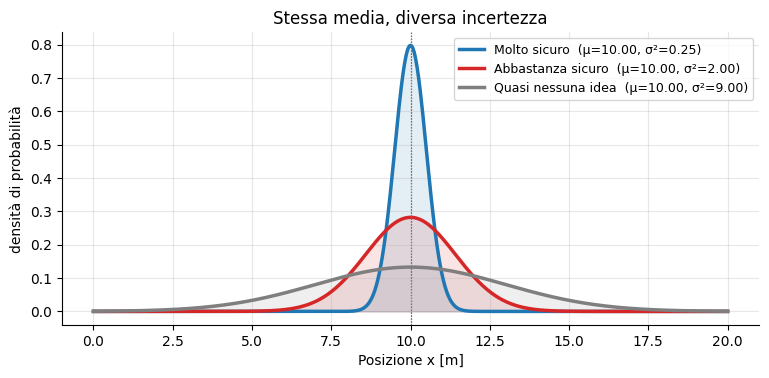

In [5]:
plot_gaussians([
    (10, 0.25, "Molto sicuro",  C_POST, "-"),
    (10, 2.0,  "Abbastanza sicuro", C_PRED, "-"),
    (10, 9.0,  "Quasi nessuna idea", C_PRIOR, "-"),
], x=np.linspace(0, 20, 800), title="Stessa media, diversa incertezza")
plt.show()

**Domanda per la classe:** se all'inizio *non sappiamo nulla* della nostra posizione, che varianza dovremmo usare?

<details><summary>Risposta</summary>

Una varianza **enorme** (es. $\sigma^2 = 1000$). La Gaussiana diventa quasi piatta: "potrei essere ovunque"
</details>

---
## Parte 2 — Cammino a occhi chiusi (solo Predict)

 Partiamo da $x=0$ (abbastanza sicuri: $\sigma^2 = 0.5$) e camminiamo a **1 m/s** per 4 secondi, **senza guardare**.

Ad ogni secondo applichiamo il modello cinematico $p' = p + v\,\Delta t$, quindi $u = 1$ m. Però i passi non sono perfetti: ogni passo aggiunge un'incertezza $\sigma_u^2 = 0.5$.

t=0  ->  μ = 0.0 m,  σ² = 0.50,  σ = 0.71 m
t=1  ->  μ = 1.0 m,  σ² = 1.00,  σ = 1.00 m
t=2  ->  μ = 2.0 m,  σ² = 1.50,  σ = 1.22 m
t=3  ->  μ = 3.0 m,  σ² = 2.00,  σ = 1.41 m
t=4  ->  μ = 4.0 m,  σ² = 2.50,  σ = 1.58 m


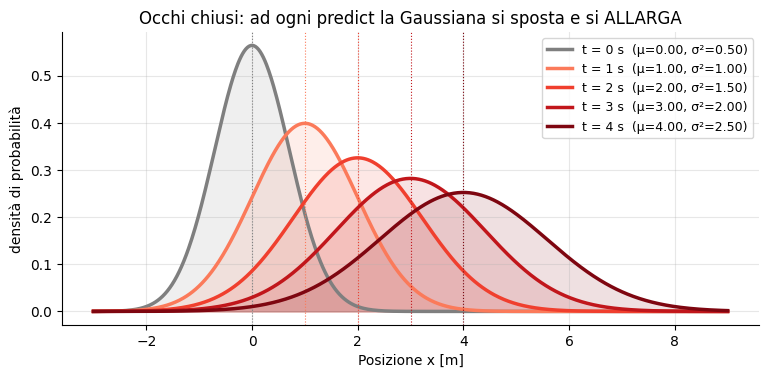

In [6]:
mu, var = 0.0, 0.5          # stato iniziale
u, var_u = 1.0, 0.5         # modello: 1 m per passo, con incertezza 0.5

curves = [(mu, var, "t = 0 s", C_PRIOR, "-")]
print(f"t=0  ->  μ = {mu:.1f} m,  σ² = {var:.2f},  σ = {np.sqrt(var):.2f} m")

colors = plt.cm.Reds(np.linspace(0.45, 0.95, 4))
for t in range(1, 5):
    mu, var = predict(mu, var, u, var_u)
    curves.append((mu, var, f"t = {t} s", colors[t - 1], "-"))
    print(f"t={t}  ->  μ = {mu:.1f} m,  σ² = {var:.2f},  σ = {np.sqrt(var):.2f} m")

plot_gaussians(curves, x=np.linspace(-3, 9, 800),
               title="Occhi chiusi: ad ogni predict la Gaussiana si sposta e si ALLARGA")
plt.show()

### ✅ Cosa abbiamo imparato
* La **media** avanza di $u$ ad ogni passo: il modello ci dice *dove* dovremmo essere.
* La **varianza** cresce di $\sigma_u^2$ ad ogni passo: più cammino senza guardare, **meno sono sicuro**.
* La Gaussiana diventa più bassa e larga (l'area resta sempre 1).

> La predizione da sola **non può mai ridurre** l'incertezza. Serve un sensore.



In [7]:
var_100 = 0.5 + 100 * 0.5
print(f"Dopo 100 s:  σ² = {var_100:.1f}  ->  σ = {np.sqrt(var_100):.1f} m")
print("Con il 95% di probabilità sono tra", f"{100 - 2*np.sqrt(var_100):.0f} m e {100 + 2*np.sqrt(var_100):.0f} m")

Dopo 100 s:  σ² = 50.5  ->  σ = 7.1 m
Con il 95% di probabilità sono tra 86 m e 114 m


---
## Parte 3 —  Apro gli occhi (un solo Update)

Esempio dell'auto:
* le **ruote** (odometria = predizione) dicono: *"ho guidato a 50 km/h per 10 s, sono a **100 m**"*, con $\sigma^2_{\text{pred}} = 4$
* il **GPS** (misura) dice: *"sei a **103 m**"*, con $\sigma_m^2 = 2$

A chi credere? A **nessuno dei due ciecamente**: li combiniamo.

Kalman Gain  K = 4.0 / (4.0 + 2.0) = 0.667
Innovazione  z - μ_pred = 3.0 m
Nuova stima  μ = 100.0 + 0.667·3.0 = 102.00 m
Nuova varianza σ² = (1 - 0.667)·4.0 = 1.333


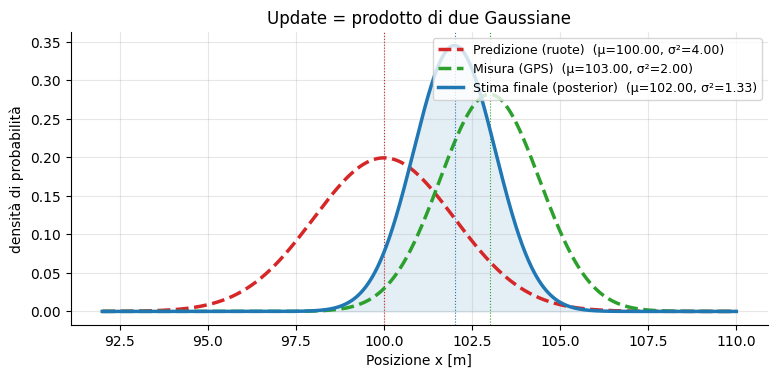

In [8]:
mu_pred, var_pred = 100.0, 4.0     # predizione (ruote)
z, var_m          = 103.0, 2.0     # misura (GPS)

mu_new, var_new, K = update(mu_pred, var_pred, z, var_m)

print(f"Kalman Gain  K = {var_pred} / ({var_pred} + {var_m}) = {K:.3f}")
print(f"Innovazione  z - μ_pred = {z - mu_pred:.1f} m")
print(f"Nuova stima  μ = {mu_pred} + {K:.3f}·{z - mu_pred:.1f} = {mu_new:.2f} m")
print(f"Nuova varianza σ² = (1 - {K:.3f})·{var_pred} = {var_new:.3f}")

plot_gaussians([
    (mu_pred, var_pred, "Predizione (ruote)", C_PRED, "--"),
    (z, var_m, "Misura (GPS)", C_MEAS, "--"),
    (mu_new, var_new, "Stima finale (posterior)", C_POST, "-"),
], x=np.linspace(92, 110, 800), title="Update = prodotto di due Gaussiane")
plt.show()

### ✅ Cosa abbiamo imparato
1. La stima finale (**102 m**) sta **tra** predizione e misura, ma **più vicina al GPS**, perché il GPS è più preciso ($\sigma_m^2 = 2 < 4$).
2. La varianza finale (**1.33**) è **più piccola di entrambe**! Combinando due informazioni incerte otteniamo un'informazione **più certa** di ognuna delle due. Questa è la magia della *sensor fusion*.



In [9]:
# Forma "media pesata" (slide 33, sinistra)
mu_w  = (var_m * mu_pred + var_pred * z) / (var_m + var_pred)
var_w = 1 / (1 / var_m + 1 / var_pred)

print(f"Forma media pesata : μ = {mu_w:.4f},  σ² = {var_w:.4f}")
print(f"Forma con K        : μ = {mu_new:.4f},  σ² = {var_new:.4f}")
print("Uguali?", np.isclose(mu_w, mu_new) and np.isclose(var_w, var_new))

Forma media pesata : μ = 102.0000,  σ² = 1.3333
Forma con K        : μ = 102.0000,  σ² = 1.3333
Uguali? True


---
## Parte 4 — Il Kalman Gain: chi ha ragione?

$K$ è una **bilancia** . Dipende solo dal **rapporto** tra le due incertezze:

$$K = \frac{\sigma^2_{\text{pred}}}{\sigma^2_{\text{pred}} + \sigma_m^2}$$

* $\sigma_m^2 \ll \sigma^2_{\text{pred}}$ (sensore molto preciso) ⇒ $K \to 1$ ⇒ **credo alla misura**
* $\sigma_m^2 \gg \sigma^2_{\text{pred}}$ (sensore molto rumoroso) ⇒ $K \to 0$ ⇒ **credo al modello**

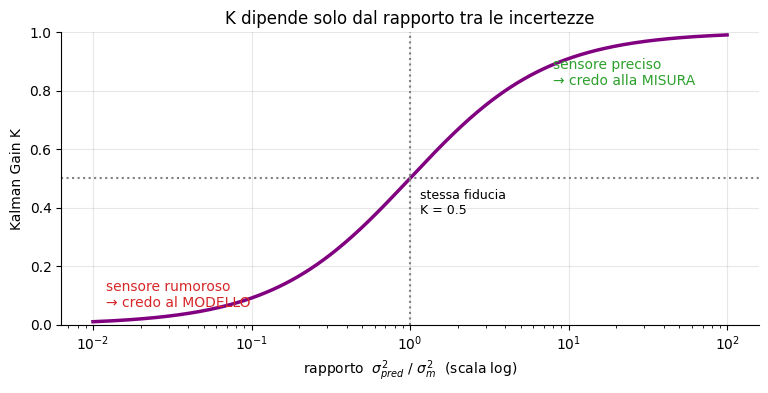

In [10]:
ratio = np.logspace(-2, 2, 400)          # σ²_pred / σ²_m
K_curve = ratio / (ratio + 1)

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.semilogx(ratio, K_curve, color="purple", lw=2.5)
ax.axhline(0.5, color="gray", ls=":"); ax.axvline(1, color="gray", ls=":")
ax.annotate("sensore rumoroso\n→ credo al MODELLO", (0.012, 0.06), fontsize=10, color=C_PRED)
ax.annotate("sensore preciso\n→ credo alla MISURA", (8, 0.82), fontsize=10, color=C_MEAS)
ax.annotate("stessa fiducia\nK = 0.5", (1.15, 0.38), fontsize=9)
ax.set_xlabel(r"rapporto  $\sigma^2_{pred}\ /\ \sigma^2_m$  (scala log)")
ax.set_ylabel("Kalman Gain K"); ax.set_ylim(0, 1)
ax.set_title("K dipende solo dal rapporto tra le incertezze")
plt.show()

### I quattro casi della slide 32

Stesse medie (predizione in 0, misura in 2), cambiamo solo le incertezze.
Prima di eseguire: **in quale caso la stima finale sarà più vicina a 2?**

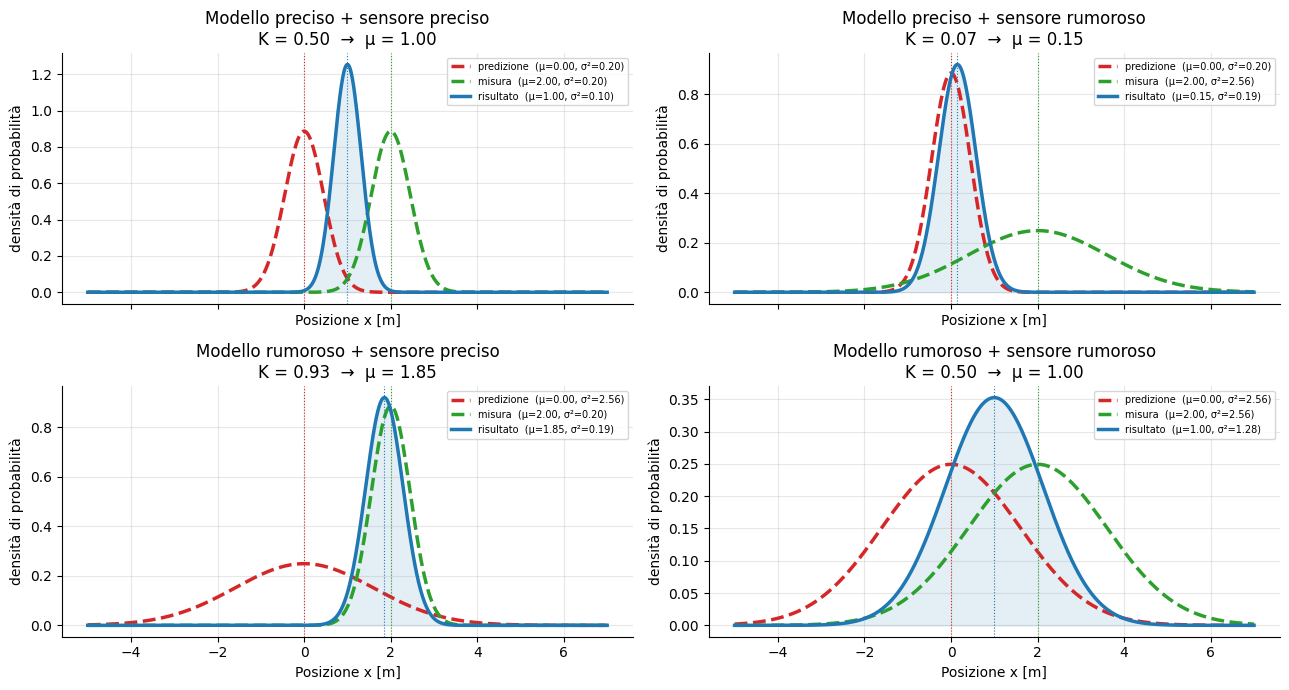

In [11]:
cases = [
    ("Modello preciso + sensore preciso", 0.45, 0.45),
    ("Modello preciso + sensore rumoroso", 0.45, 1.6),
    ("Modello rumoroso + sensore preciso", 1.6, 0.45),
    ("Modello rumoroso + sensore rumoroso", 1.6, 1.6),
]
fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex=True)
x = np.linspace(-5, 7, 800)
for ax, (name, s_pred, s_meas) in zip(axes.flat, cases):
    mu_n, var_n, K = update(0.0, s_pred**2, 2.0, s_meas**2)
    plot_gaussians([(0.0, s_pred**2, "predizione", C_PRED, "--"),
                    (2.0, s_meas**2, "misura", C_MEAS, "--"),
                    (mu_n, var_n, "risultato", C_POST, "-")],
                   x=x, ax=ax, title=f"{name}\nK = {K:.2f}  →  μ = {mu_n:.2f}")
    ax.legend(fontsize=7, loc="upper right")
plt.tight_layout(); plt.show()

### ✅ Cosa abbiamo imparato
* Il risultato si sposta sempre verso la sorgente **più affidabile**.
* Il risultato è **sempre più stretto** di entrambe le curve (anche nel caso "tutto rumoroso").
* Quando entrambe sono ugualmente affidabili, $K = 0.5$: la stima è esattamente a metà strada.

---
## Parte 5 —  Il ciclo completo: Predict → Update → Predict → …

Ora mettiamo tutto insieme:

```
Inizializzazione  →  [ Predict  →  Update ]  →  [ Predict  →  Update ]  →  ...
```

**Scenario:** la persona cammina a 1 m/s. Ad ogni secondo:
1. **Predict:** "mi sono mosso di circa 1 m" ($u = 1$, $\sigma_u^2 = 0.2$)
2. **Update:** apro gli occhi e vedo dove sono ($\sigma_m^2 = 1$)

**Inizializzazione:** *non sappiamo dove partiamo* ⇒ $\mu_0 = 0$, $\sigma_0^2 = 1000$ (come nella slide 45).

In [26]:
# Mondo reale: la persona parte da x=3 (ma il filtro NON lo sa!)
truth, zs = simulate_world(n_steps=10, v_true=1.0, var_u_true=0.2, var_m_true=1.0, x0=3.0, seed=3)

u, var_u, var_m = 1.0, 0.2, 1.0
mu, var = 0.0, 1000.0

print(f"{'t':>2} | {'fase':<8} | {'μ':>7} | {'σ²':>8} | {'K':>5} | {'z':>6} | {'verità':>6}")
print("-" * 60)
print(f"{0:>2} | {'init':<8} | {mu:7.2f} | {var:8.2f} |       |        |")
history = []
for t, (z, xt) in enumerate(zip(zs, truth), start=1):
    mu_p, var_p = predict(mu, var, u, var_u)
    print(f"{t:>2} | {'predict':<8} | {mu_p:7.2f} | {var_p:8.2f} |       |        |")
    mu, var, K = update(mu_p, var_p, z, var_m)
    print(f"{t:>2} | {'update':<8} | {mu:7.2f} | {var:8.3f} | {K:5.3f} | {z:6.2f} | {xt:6.2f}")
    history.append((mu_p, var_p, z, mu, var, K))

 t | fase     |       μ |       σ² |     K |      z | verità
------------------------------------------------------------
 0 | init     |    0.00 |  1000.00 |       |        |
 1 | predict  |    1.00 |  1000.20 |       |        |
 1 | update   |    2.36 |    0.999 | 0.999 |   2.36 |   4.91
 2 | predict  |    3.36 |     1.20 |       |        |
 2 | update   |    4.54 |    0.545 | 0.545 |   5.53 |   6.10
 3 | predict  |    5.54 |     0.75 |       |        |
 3 | update   |    6.03 |    0.427 | 0.427 |   6.68 |   6.90
 4 | predict  |    7.03 |     0.63 |       |        |
 4 | update   |    6.93 |    0.385 | 0.385 |   6.76 |   6.99
 5 | predict  |    7.93 |     0.59 |       |        |
 5 | update   |    9.04 |    0.369 | 0.369 |  10.93 |   7.61
 6 | predict  |   10.04 |     0.57 |       |        |
 6 | update   |    9.43 |    0.363 | 0.363 |   8.36 |   8.71
 7 | predict  |   10.43 |     0.56 |       |        |
 7 | update   |    9.88 |    0.360 | 0.360 |   8.91 |   9.58
 8 | predict  |   1

Guardiamo i primi passi **graficamente**: ad ogni passo vediamo la predizione (rossa), la misura (verde) e il risultato (blu).

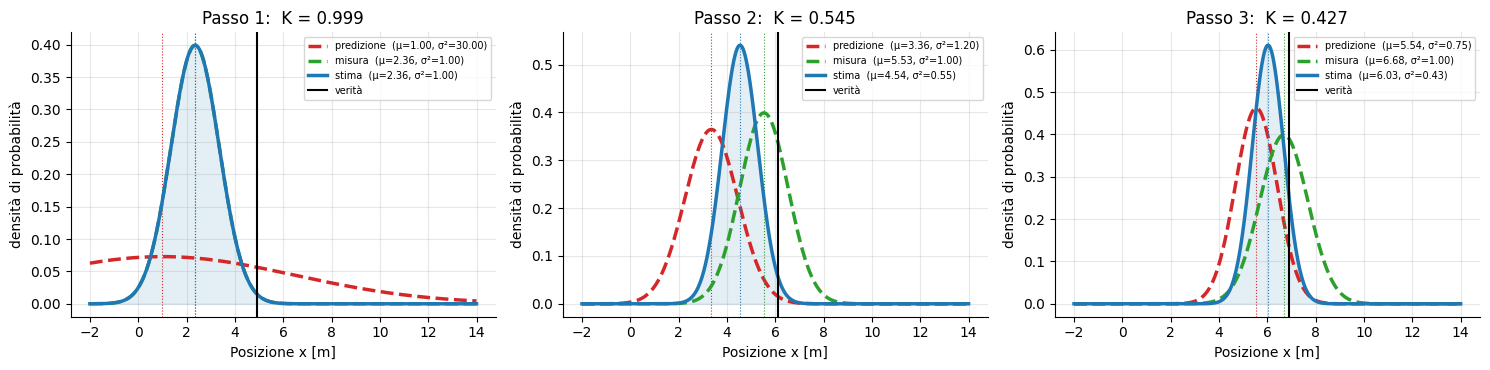

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for i, ax in enumerate(axes):
    mu_p, var_p, z, mu_n, var_n, K = history[i]
    var_p_plot = min(var_p, 30)   # al passo 1 la predizione è piatta: la "tagliamo" per vederla
    plot_gaussians([(mu_p, var_p_plot, "predizione", C_PRED, "--"),
                    (z, var_m, "misura", C_MEAS, "--"),
                    (mu_n, var_n, "stima", C_POST, "-")],
                   x=np.linspace(-2, 14, 800), ax=ax,
                   title=f"Passo {i+1}:  K = {K:.3f}")
    ax.axvline(truth[i], color=C_TRUE, lw=1.5, label="verità")
    ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

### ✅ Cosa abbiamo imparato

* **Passo 1:** $K \approx 1$. Non sapendo nulla ($\sigma^2 = 1000$), il filtro **si fida completamente della prima misura**. Ecco perché possiamo inizializzare con un valore qualsiasi: il filtro si "aggancia" da solo.
* **Passi successivi:** la varianza scende rapidamente e $K$ diminuisce: man mano che il filtro diventa sicuro di sé, dà meno peso alle singole misure rumorose.
* Dopo pochi passi $K$ e $\sigma^2$ **si stabilizzano** (regime stazionario): l'aumento di incertezza della predict è bilanciato dalla riduzione dell'update.

Vediamolo su una camminata più lunga (30 passi).

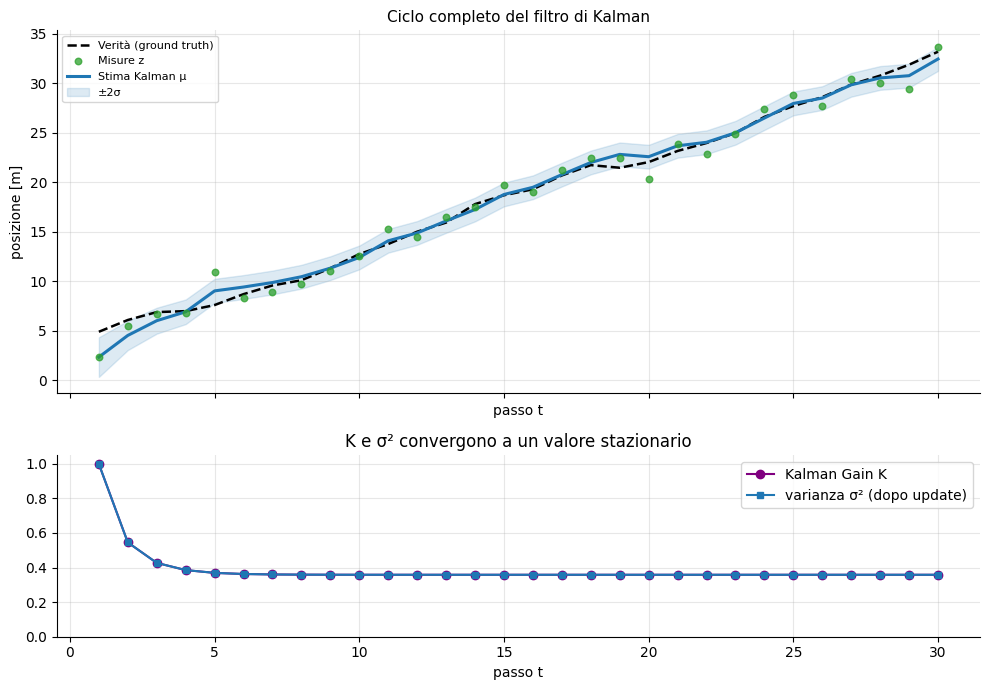

Errore (RMSE) delle misure grezze : 1.144 m
Errore (RMSE) della stima Kalman  : 0.764 m
K stazionario ≈ 0.358


In [14]:
truth, zs = simulate_world(n_steps=30, v_true=1.0, var_u_true=0.2, var_m_true=1.0, x0=3.0, seed=3)
mus, vars_, Ks = run_kalman(zs, u=1.0, var_u=0.2, var_m=1.0, mu0=0.0, var0=1000.0)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True,
                               gridspec_kw={"height_ratios": [2, 1]})
plot_run(truth, zs, mus, vars_, title="Ciclo completo del filtro di Kalman", ax=ax1)
t = np.arange(1, 31)
ax2.plot(t, Ks, "o-", color="purple", label="Kalman Gain K")
ax2.plot(t, vars_, "s-", color=C_POST, ms=4, label="varianza σ² (dopo update)")
ax2.set_ylim(0, 1.05); ax2.set_xlabel("passo t"); ax2.legend()
ax2.set_title("K e σ² convergono a un valore stazionario")
plt.tight_layout(); plt.show()

print(f"Errore (RMSE) delle misure grezze : {rmse(zs, truth):.3f} m")
print(f"Errore (RMSE) della stima Kalman  : {rmse(mus, truth):.3f} m")
print(f"K stazionario ≈ {Ks[-1]:.3f}")

> Il filtro ha un errore **più basso delle misure stesse**: sta *filtrando* il rumore del sensore usando la conoscenza del moto.

---
## Parte 6 — Gli occhiali sbagliati (sensore rumoroso)

Stessa persona, stessa camminata, ma ora confrontiamo due sensori:
* **Occhiali giusti:** $\sigma_m^2 = 0.5$
* **Occhiali sbagliati:** $\sigma_m^2 = 25$

**Prima di eseguire:** con gli occhiali sbagliati, $K$ sarà più grande o più piccolo? La stima seguirà di più le misure o il modello?

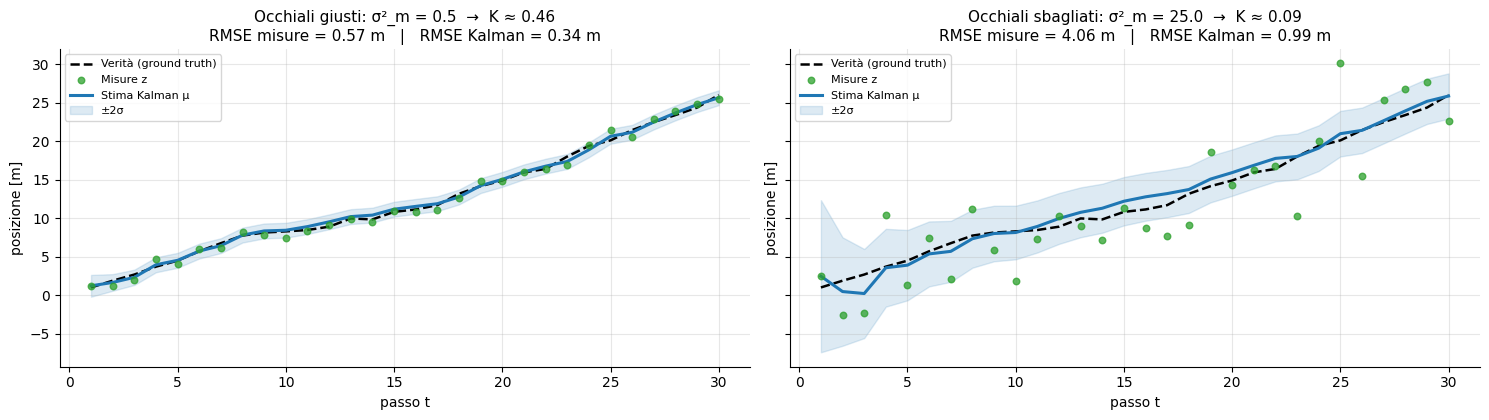

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.3), sharey=True)
for ax, (name, vm) in zip(axes, [("Occhiali giusti", 0.5), ("Occhiali sbagliati", 25.0)]):
    truth, zs = simulate_world(30, v_true=1.0, var_u_true=0.2, var_m_true=vm, seed=7)
    mus, vars_, Ks = run_kalman(zs, u=1.0, var_u=0.2, var_m=vm, mu0=0.0, var0=1000.0)
    plot_run(truth, zs, mus, vars_, ax=ax,
             title=f"{name}: σ²_m = {vm}  →  K ≈ {Ks[-1]:.2f}\n"
                   f"RMSE misure = {rmse(zs, truth):.2f} m   |   RMSE Kalman = {rmse(mus, truth):.2f} m")
plt.tight_layout(); plt.show()

### ✅ Cosa abbiamo imparato
* Con occhiali **giusti** $K$ è alto: la stima segue da vicino le misure.
* Con occhiali **sbagliati** $K$ è basso: il filtro **ignora gran parte del rumore** e si affida al modello di moto. Le misure sono sparse ovunque, ma la stima blu resta liscia e vicina alla verità.
* Più il sensore è rumoroso, **più il filtro è utile** (confronta i due RMSE).

---
## Parte 7 —  Il sensore sparisce (solo predizione)

*Slide 3 (il problema della latenza) e slide 22 (filtro asincrono).*

In questo esempio il sensore **non manda misure** (galleria, occlusione, il thread di clustering è in ritardo…). Il filtro può continuare a fornire una stima? **Sì**: esegue solo la predict.

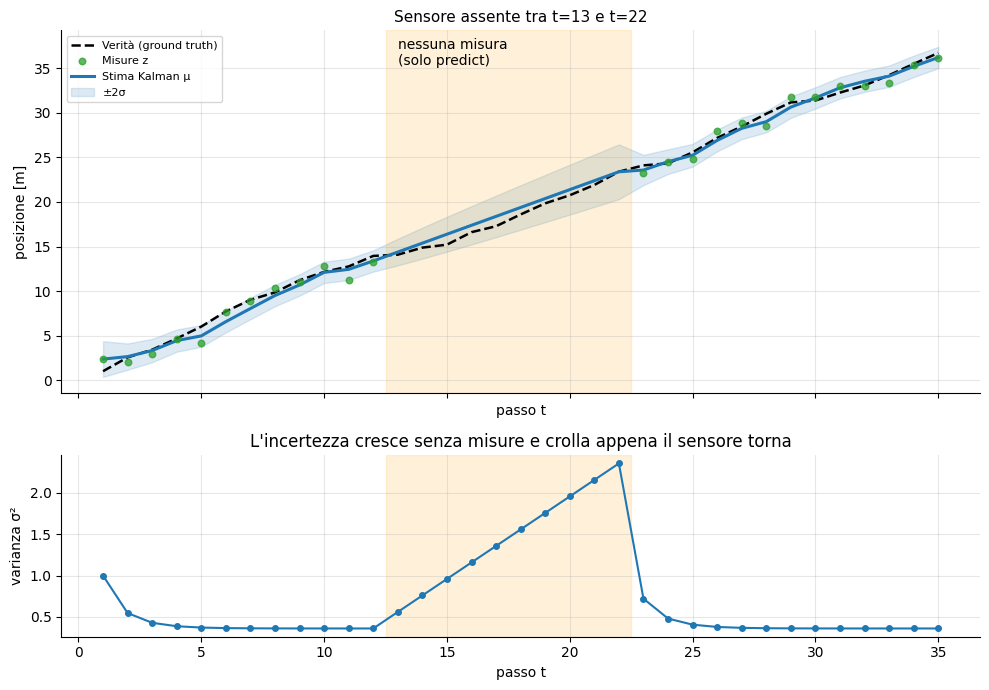

In [33]:
truth, zs_full = simulate_world(35, v_true=1.0, var_u_true=0.2, var_m_true=1.0, seed=11)
zs = [None if 12 <= t < 22 else z for t, z in enumerate(zs_full)]   # buco nelle misure

mus, vars_, Ks = run_kalman(zs, u=1.0, var_u=0.2, var_m=1.0, mu0=0.0, var0=1000.0)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True,
                               gridspec_kw={"height_ratios": [2, 1]})
plot_run(truth, zs, mus, vars_, ax=ax1, title="Sensore assente tra t=13 e t=22")
for ax in (ax1, ax2):
    ax.axvspan(12.5, 22.5, color="orange", alpha=0.15)
ax1.text(13, ax1.get_ylim()[1] * 0.9, "nessuna misura\n(solo predict)", fontsize=10)
t = np.arange(1, 36)
ax2.plot(t, vars_, "o-", color=C_POST, ms=4)
ax2.set_ylabel("varianza σ²"); ax2.set_xlabel("passo t")
ax2.set_title("L'incertezza cresce senza misure e crolla appena il sensore torna")
plt.tight_layout(); plt.show()

### ✅ Cosa abbiamo imparato
* Senza misure il filtro **continua a stimare** grazie al modello: la banda di incertezza si allarga in modo "onesto".
* Alla prima misura disponibile, $\sigma^2_{\text{pred}}$ è grande ⇒ $K$ è grande ⇒ il filtro si **ri-aggancia** subito alla realtà.
* È esattamente ciò che serve al *path planner* della slide 3: può chiedere la posizione dell'oggetto **in qualsiasi istante**, anche tra una misura e l'altra, e ottenere una stima con la sua incertezza.

---
## Parte 8 —  Il pavimento scivola (modello sbagliato)

"cosa succede se il mio modello cinematico è sbagliato? se il pavimento scivola?"*

Il filtro crede che la persona cammini a **1.0 m/s**, ma in realtà (pavimento scivoloso, nastro trasportatore…) si muove a **1.4 m/s**.

Confrontiamo due filtri con lo **stesso modello sbagliato** ($u = 1.0$) ma diversa $\sigma_u^2$:
* **Filtro A (presuntuoso):** $\sigma_u^2 = 0.01$ — "il mio modello è perfetto"
* **Filtro B (umile):** $\sigma_u^2 = 0.5$ — "il mio modello potrebbe sbagliare"

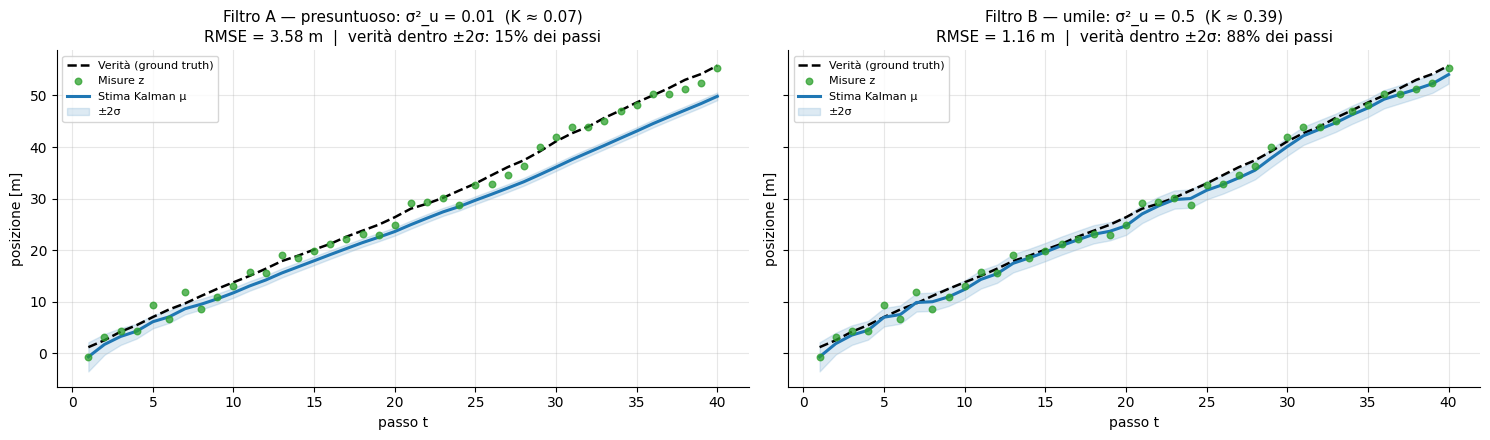

In [17]:
truth, zs = simulate_world(40, v_true=1.4, var_u_true=0.05, var_m_true=2.0, seed=5)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for ax, (name, vu) in zip(axes, [("A — presuntuoso", 0.01), ("B — umile", 0.5)]):
    mus, vars_, Ks = run_kalman(zs, u=1.0, var_u=vu, var_m=2.0, mu0=0.0, var0=1000.0)
    inside = np.mean(np.abs(truth - mus) <= 2 * np.sqrt(vars_)) * 100
    plot_run(truth, zs, mus, vars_, ax=ax,
             title=f"Filtro {name}: σ²_u = {vu}  (K ≈ {Ks[-1]:.2f})\n"
                   f"RMSE = {rmse(mus, truth):.2f} m  |  verità dentro ±2σ: {inside:.0f}% dei passi")
plt.tight_layout(); plt.show()

###  Cosa abbiamo imparato
* Il filtro **A** è troppo sicuro del suo modello: $K$ è piccolo, ignora le misure che gli dicono "stai andando più veloce", e accumula un **ritardo sistematico**. Peggio ancora: la sua banda di incertezza è stretta e **non contiene la verità** → il filtro è **sicuro di sé e sbagliato**, la situazione più pericolosa in un'auto a guida autonoma.
* Il filtro **B** ammette che il modello può sbagliare: $K$ è più alto, le misure correggono l'errore del modello.

> $\sigma_u^2$ non rappresenta solo il "rumore" del moto, ma anche **tutto ciò che il modello non sa** (attriti, accelerazioni, pendenze…). Sottostimarla è un errore molto comune.

---
## Parte 9 —  Laboratorio interattivo

Ora sei tu a fare il *tuning* del filtro. Il **mondo reale è fisso** (non cambia quando muovi gli slider):
* velocità vera = **1.2 m/s**, rumore di moto vero $\sigma^2 = 0.3$, rumore del sensore vero $\sigma^2 = 4$

Gli slider controllano **cosa crede il filtro**:

| Slider | Significato |
|---|---|
| `u_modello` | velocità che il filtro *crede* (prova a metterla diversa da 1.2!) |
| `var_u` | quanto il filtro si fida del modello ($\sigma_u^2$) |
| `var_m` | quanto il filtro si fida del sensore ($\sigma_m^2$) |
| `var_0` | incertezza iniziale |
| `dropout` | spegne il sensore tra i passi 20 e 30 |

### Sfide
1. Metti `var_m = 0.1` (il filtro crede che il sensore sia perfetto). Cosa succede alla stima?
2. Metti `var_m = 50`. Cosa succede?
3. Metti `u_modello = 0.8` e prova a "salvare" il filtro solo con `var_u`.
4. Metti `var_0 = 0.1` con `mu_0 = 0` ma la persona parte da 5 m: quanto ci mette il filtro ad agganciarsi?

In [18]:
from ipywidgets import interact, FloatSlider, Checkbox, Layout

# Mondo reale FISSO
N_LAB = 50
# ZS_LAB è l'array delle 50 misure e TRUTH_LAB la traiettoria vera corrispondente.

TRUTH_LAB, ZS_LAB = simulate_world(N_LAB, v_true=1.2, var_u_true=0.3, var_m_true=4.0, x0=5.0, seed=42)

def laboratorio(u_modello=1.2, var_u=0.3, var_m=4.0, var_0=100.0, dropout=False):
    zs = [None if (dropout and 20 <= t < 30) else z for t, z in enumerate(ZS_LAB)]
    mus, vars_, Ks = run_kalman(zs, u=u_modello, var_u=var_u, var_m=var_m, mu0=0.0, var0=var_0)
    z_err = rmse([z for z in zs if z is not None],
                 [x for x, z in zip(TRUTH_LAB, zs) if z is not None])

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True,
                                   gridspec_kw={"height_ratios": [2.2, 1]})
    plot_run(TRUTH_LAB, zs, mus, vars_, ax=ax1,
             title=f"RMSE Kalman = {rmse(mus, TRUTH_LAB):.2f} m    (RMSE misure grezze = {z_err:.2f} m)")
    err = np.abs(TRUTH_LAB - mus)
    t = np.arange(1, N_LAB + 1)
    ax2.plot(t, err, color="crimson", lw=2, label="|errore|")
    ax2.plot(t, 2 * np.sqrt(vars_), "--", color=C_POST, label="2σ dichiarata dal filtro")
    ax2b = ax2.twinx()
    ax2b.plot(t, Ks, ":", color="purple", lw=2, label="K"); ax2b.set_ylim(0, 1.05)
    ax2b.set_ylabel("K", color="purple"); ax2b.grid(False)
    if dropout:
        for ax in (ax1, ax2):
            ax.axvspan(20.5, 30.5, color="orange", alpha=0.15)
    ax2.set_xlabel("passo t"); ax2.set_ylabel("errore [m]")
    ax2.legend(loc="upper left", fontsize=8); ax2b.legend(loc="upper right", fontsize=8)
    ax2.set_title("Se l'errore rosso supera spesso la linea blu, il filtro è troppo sicuro di sé")
    plt.tight_layout(); plt.show()

L = Layout(width="480px"); S = {"description_width": "110px"}
interact(laboratorio,
         u_modello=FloatSlider(value=1.2, min=0.5, max=2.0, step=0.05, description="u_modello", layout=L, style=S),
         var_u=FloatSlider(value=0.3, min=0.01, max=5.0, step=0.01, description="var_u (moto)", layout=L, style=S),
         var_m=FloatSlider(value=4.0, min=0.1, max=50.0, step=0.1, description="var_m (sensore)", layout=L, style=S),
         var_0=FloatSlider(value=100.0, min=0.1, max=1000.0, step=0.1, description="var_0 (iniziale)", layout=L, style=S),
         dropout=Checkbox(value=False, description="Sensore spento (t=20..30)"));

interactive(children=(FloatSlider(value=1.2, description='u_modello', layout=Layout(width='480px'), max=2.0, m…

### Esercizio  — Due sensori (sensor fusion)
La persona ha **due** sensori: una telecamera ($\sigma^2 = 2$) e un GPS ($\sigma^2 = 5$). Ad ogni passo arrivano entrambe le misure.

**Suggerimento:** dopo la predict, basta fare **due update di fila** (prima con una misura, poi con l'altra). Completa la funzione e confronta l'RMSE con il caso a un solo sensore.

In [34]:
def run_kalman_2sensori(zs_cam, zs_gps, u, var_u, var_cam, var_gps, mu0, var0):
    mus, vars_ = [], []
    mu, var = mu0, var0
    for z1, z2 in zip(zs_cam, zs_gps):
        mu, var = predict(mu, var, u, var_u)
        # TODO: update con la telecamera
        # TODO: update con il GPS
        mus.append(mu); vars_.append(var)
    return np.array(mus), np.array(vars_)

# Generazione dei dati (stessa verità, due sensori diversi)
rng = np.random.default_rng(0)
truth, zs_cam = simulate_world(40, v_true=1.0, var_u_true=0.2, var_m_true=2.0, seed=21)
zs_gps = truth + rng.normal(0, np.sqrt(5.0), size=truth.shape)


# Confronto: solo telecamera, solo GPS, entrambi
mus_cam, vars_cam, _ = run_kalman(zs_cam, u=1.0, var_u=0.2, var_m=2.0, mu0=0.0, var0=1000.0)
mus_gps, vars_gps, _ = run_kalman(zs_gps, u=1.0, var_u=0.2, var_m=5.0, mu0=0.0, var0=1000.0)
mus2, vars2 = run_kalman_2sensori(zs_cam, zs_gps, 1.0, 0.2, 2.0, 5.0, 0.0, 1000.0)

print(f"{'':<16}{'RMSE':>8}{'σ² finale':>12}")
print(f"{'Solo telecamera':<16}{rmse(mus_cam, truth):8.2f}{vars_cam[-1]:12.2f}")
print(f"{'Solo GPS':<16}{rmse(mus_gps, truth):8.2f}{vars_gps[-1]:12.2f}")
print(f"{'Entrambi':<16}{rmse(mus2, truth):8.2f}{vars2[-1]:12.2f}")